In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("vyshnavkumars/pcb-component-detection-dataset-yolo-format")

print("Path to dataset files:", path)

100%|██████████| 682M/682M [00:08<00:00, 88.9MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/vyshnavkumars/pcb-component-detection-dataset-yolo-format/versions/1


Đang đọc và phân tích dữ liệu... Vui lòng đợi.

BÁO CÁO TỔNG QUAN EDA
- Tổng số ảnh: 460
- Tổng số object: 6630
- Số object trung bình trên mỗi ảnh: 14.41
- Ảnh có nhiều object nhất: 15 objects (File: crop_442)
- Mức độ mất cân bằng: Class nhiều nhất (capacitor) gấp 36.38 lần class ít nhất (transistor)


/tmp/ipykernel_1424/2557416383.py:95: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_bbox, x='class', order=df_bbox['class'].value_counts().index, palette='viridis')


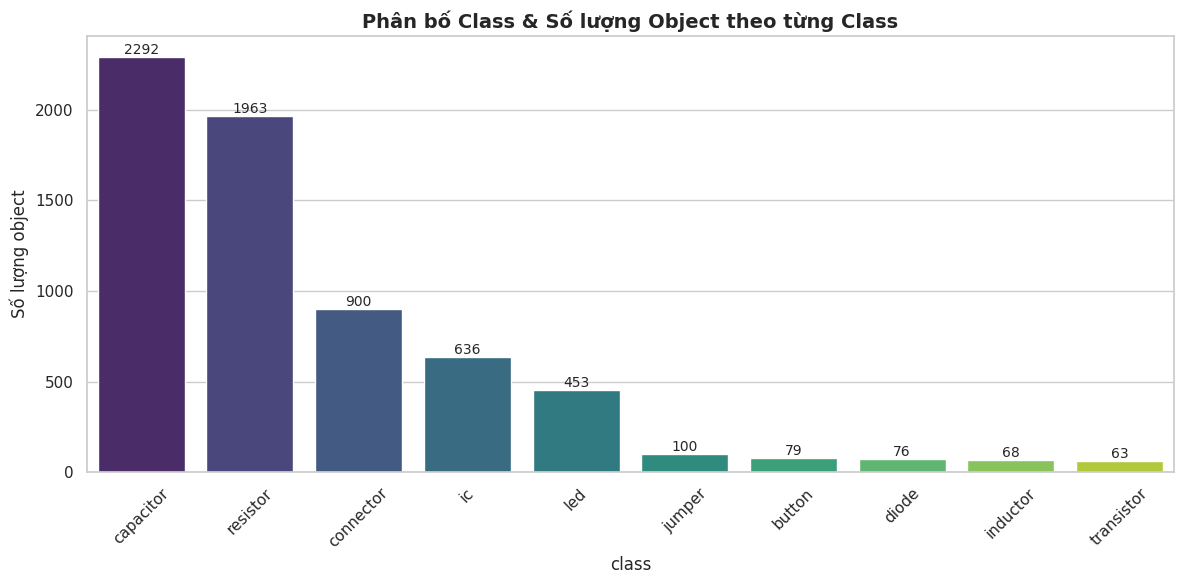

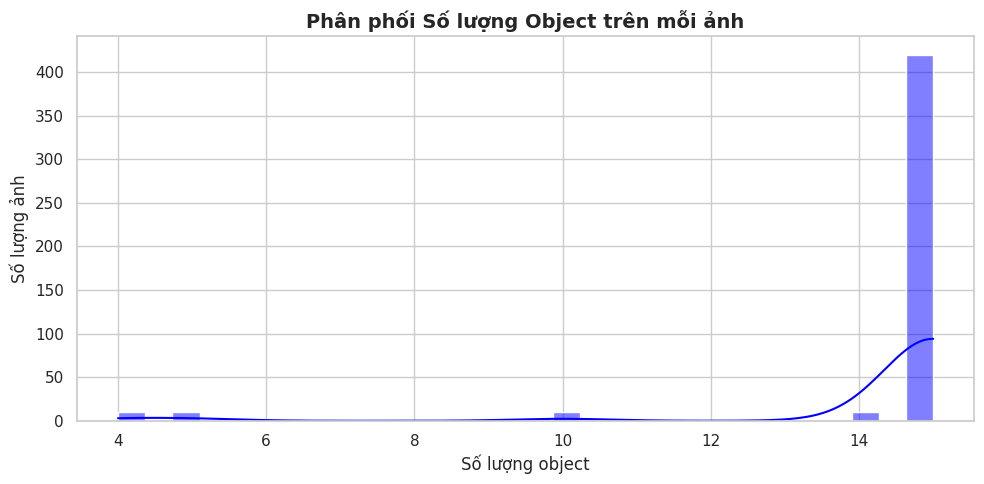

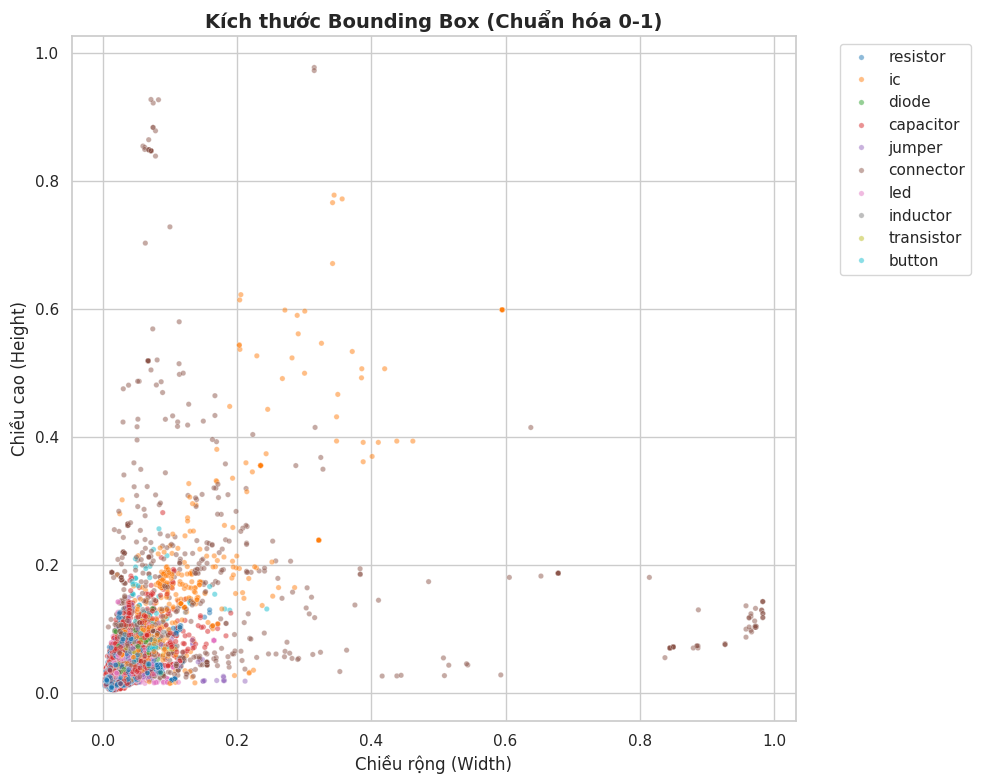

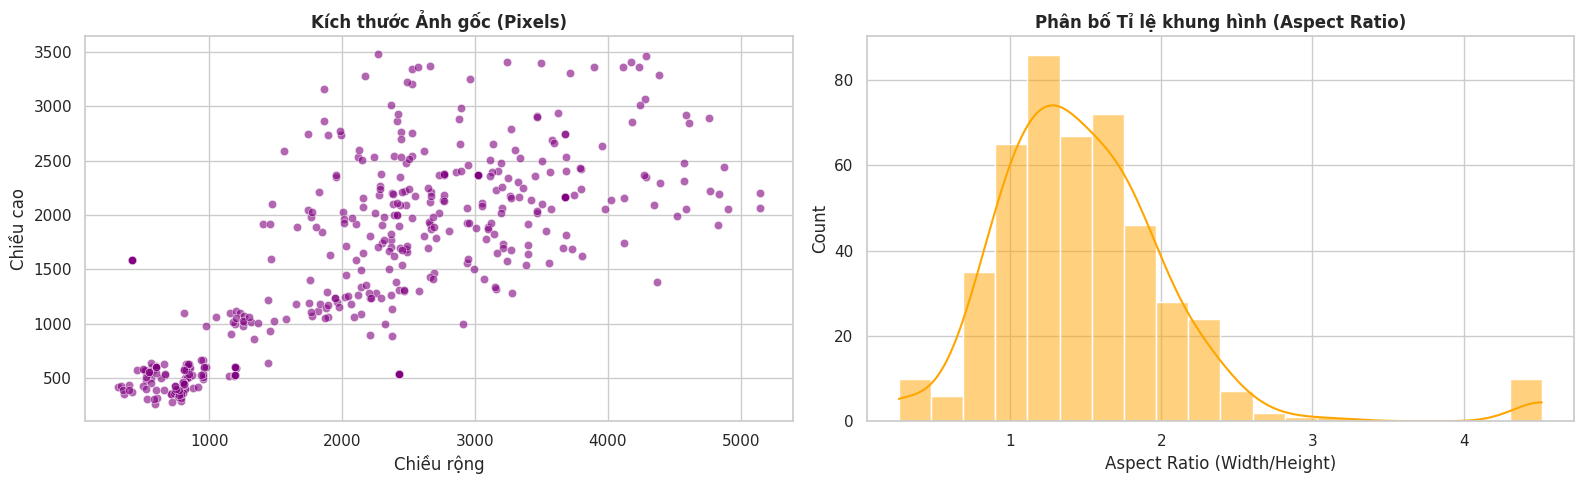

/tmp/ipykernel_1424/2557416383.py:141: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_bbox, x='class', y='bbox_area', palette='Set2')


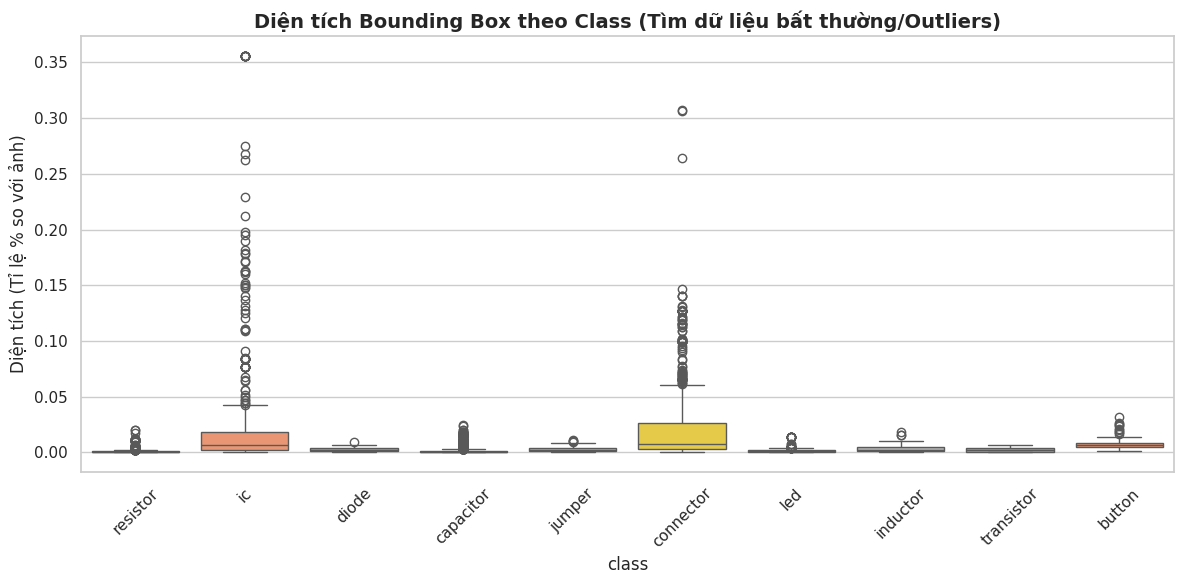

In [3]:
import os
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import numpy as np

# 1. CẤU HÌNH BAN ĐẦU
DATASET_PATH = "/root/.cache/kagglehub/datasets/vyshnavkumars/pcb-component-detection-dataset-yolo-format/versions/1/pcb_yolo_cropped"
CLASSES = ['resistor', 'capacitor', 'connector', 'ic', 'led', 'diode', 'transistor', 'inductor', 'jumper', 'button']

def run_eda(dataset_path, classes):
    base_path = Path(dataset_path)
    img_dir = base_path / 'images'
    lbl_dir = base_path / 'labels'

    # Thu thập đường dẫn
    img_paths = []
    for ext in ('*.jpg', '*.jpeg', '*.png'):
        img_paths.extend(img_dir.rglob(ext))

    labels_dict = {p.stem: p for p in lbl_dir.rglob('*.txt')}

    # Khởi tạo các list để lưu dữ liệu thống kê
    image_data = [] # Lưu thông tin ảnh: width, height, aspect_ratio, num_objects
    bbox_data = []  # Lưu thông tin bbox: class, w, h, area

    print("Đang đọc và phân tích dữ liệu... Vui lòng đợi.")

    for img_path in img_paths:
        stem = img_path.stem
        lbl_path = labels_dict.get(stem)

        # Đọc kích thước ảnh
        img = cv2.imread(str(img_path))
        if img is None: continue
        h_img, w_img, _ = img.shape
        aspect_ratio = w_img / h_img if h_img > 0 else 0

        num_objects = 0

        if lbl_path and lbl_path.exists():
            with open(lbl_path, 'r') as f:
                lines = f.readlines()
                num_objects = len(lines)

                for line in lines:
                    parts = line.strip().split()
                    if len(parts) == 5:
                        class_id = int(parts[0])
                        class_name = classes[class_id] if 0 <= class_id < len(classes) else "Unknown"
                        w_box, h_box = float(parts[3]), float(parts[4])
                        area = w_box * h_box

                        bbox_data.append({
                            'image_name': stem,
                            'class': class_name,
                            'bbox_w': w_box,
                            'bbox_h': h_box,
                            'bbox_area': area
                        })

        image_data.append({
            'image_name': stem,
            'img_w': w_img,
            'img_h': h_img,
            'aspect_ratio': aspect_ratio,
            'num_objects': num_objects
        })

    # Chuyển thành DataFrame để dễ phân tích
    df_img = pd.DataFrame(image_data)
    df_bbox = pd.DataFrame(bbox_data)

    # ---------------------------------------------------------
    # 2. IN BÁO CÁO THỐNG KÊ (TEXT)
    # ---------------------------------------------------------
    print("\n" + "="*50)
    print("BÁO CÁO TỔNG QUAN EDA")
    print("="*50)
    print(f"- Tổng số ảnh: {len(df_img)}")
    print(f"- Tổng số object: {len(df_bbox)}")
    print(f"- Số object trung bình trên mỗi ảnh: {df_img['num_objects'].mean():.2f}")
    print(f"- Ảnh có nhiều object nhất: {df_img['num_objects'].max()} objects (File: {df_img.loc[df_img['num_objects'].idxmax(), 'image_name']})")
    print(f"- Mức độ mất cân bằng: Class nhiều nhất ({df_bbox['class'].value_counts().index[0]}) gấp {df_bbox['class'].value_counts().iloc[0] / df_bbox['class'].value_counts().iloc[-1]:.2f} lần class ít nhất ({df_bbox['class'].value_counts().index[-1]})")

    # ---------------------------------------------------------
    # 3. TRỰC QUAN HÓA (VISUALIZATION)
    # ---------------------------------------------------------
    sns.set_theme(style="whitegrid")

    # Hình 1: Phân bố class và Số lượng object
    plt.figure(figsize=(12, 6))
    ax = sns.countplot(data=df_bbox, x='class', order=df_bbox['class'].value_counts().index, palette='viridis')
    plt.title('Phân bố Class & Số lượng Object theo từng Class', fontsize=14, fontweight='bold')
    plt.xticks(rotation=45)
    plt.ylabel('Số lượng object')
    for p in ax.patches:
        ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=10)
    plt.tight_layout()
    plt.show()

    # Hình 2: Phân phối số lượng object trên mỗi ảnh
    plt.figure(figsize=(10, 5))
    sns.histplot(df_img['num_objects'], bins=30, kde=True, color='blue')
    plt.title('Phân phối Số lượng Object trên mỗi ảnh', fontsize=14, fontweight='bold')
    plt.xlabel('Số lượng object')
    plt.ylabel('Số lượng ảnh')
    plt.tight_layout()
    plt.show()

    # Hình 3: Phân phối kích thước Bounding Box (Width vs Height)
    plt.figure(figsize=(10, 8))
    sns.scatterplot(data=df_bbox, x='bbox_w', y='bbox_h', hue='class', alpha=0.5, palette='tab10', s=15)
    plt.title('Kích thước Bounding Box (Chuẩn hóa 0-1)', fontsize=14, fontweight='bold')
    plt.xlabel('Chiều rộng (Width)')
    plt.ylabel('Chiều cao (Height)')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

    # Hình 4: Phân phối kích thước ảnh (Width vs Height) và Aspect Ratio
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    sns.scatterplot(data=df_img, x='img_w', y='img_h', ax=axes[0], color='purple', alpha=0.6)
    axes[0].set_title('Kích thước Ảnh gốc (Pixels)', fontweight='bold')
    axes[0].set_xlabel('Chiều rộng')
    axes[0].set_ylabel('Chiều cao')

    sns.histplot(df_img['aspect_ratio'], bins=20, kde=True, ax=axes[1], color='orange')
    axes[1].set_title('Phân bố Tỉ lệ khung hình (Aspect Ratio)', fontweight='bold')
    axes[1].set_xlabel('Aspect Ratio (Width/Height)')

    plt.tight_layout()
    plt.show()

    # Hình 5: Dữ liệu bất thường (Boxplot diện tích bounding box để tìm object quá to/nhỏ)
    plt.figure(figsize=(12, 6))
    sns.boxplot(data=df_bbox, x='class', y='bbox_area', palette='Set2')
    plt.title('Diện tích Bounding Box theo Class (Tìm dữ liệu bất thường/Outliers)', fontsize=14, fontweight='bold')
    plt.xticks(rotation=45)
    plt.ylabel('Diện tích (Tỉ lệ % so với ảnh)')
    plt.tight_layout()
    plt.show()

# Thực thi
run_eda(DATASET_PATH, CLASSES)